In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_curve
from sklearn.metrics import auc
from sklearn.model_selection import KFold

In [7]:
dataset_url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"

df = pd.read_csv(dataset_url)
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [11]:
df.shape

(5000, 9)

In [13]:
df.dtypes

lead_source                  object
industry                     object
employment_status            object
location                     object
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [15]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [17]:
# Data preparation

categorical_features = [
    "lead_source",
    "industry",
    "employment_status",
    "location"
]

numerical_features = [
    "annual_income",
    "lead_score"
]

df[categorical_features] = df[categorical_features].fillna("NA")
df[numerical_features] = df[numerical_features].fillna(0.0)

In [19]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [21]:
# Split the data

df_full_train, df_test = train_test_split(
    df, 
    test_size=0.2, 
    random_state=1
)

df_train, df_val = train_test_split(
    df_full_train, 
    test_size=0.25, 
    random_state=1
)

len(df_train), len(df_val), len(df_test)

(3000, 1000, 1000)

In [23]:
# Separate target variable

y_train = df_train["converted"].values
y_val = df_val["converted"].values
y_test = df_test["converted"].values

# Remove converted from dataframe

del df_train['converted']
del df_val['converted']
del df_test['converted']

In [31]:
# Question 1: ROC AUC feature importance

from sklearn.metrics import roc_auc_score

print("lead_score", roc_auc_score(y_train, df_train["lead_score"]))
print("number_of_courses_viewed", roc_auc_score(y_train, df_train["number_of_courses_viewed"]))
print("interaction_count", roc_auc_score(y_train, df_train["interaction_count"]))
print("annual_income", roc_auc_score(y_train, df_train["annual_income"]))

lead_score 0.7882254810906102
number_of_courses_viewed 0.7229894623989618
interaction_count 0.7649203047563227
annual_income 0.6081977776250831


In [43]:
# Question 2: Model AUC

from sklearn.feature_extraction import DictVectorizer

dv = DictVectorizer(sparse=True)

train_dicts = df_train.to_dict(orient="records")
val_dicts = df_val.to_dict(orient="records")

X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

In [45]:
model = LogisticRegression(
    solver="liblinear",
    C=1.0,
    max_iter=1000 
)

model.fit(X_train, y_train)

LogisticRegression(max_iter=1000, solver='liblinear')

In [47]:
y_pred = model.predict_proba(X_val)[:, 1]

In [49]:
roc_auc_score(y_val, y_pred)

0.7318222288173319

In [55]:
# Question 3: Precision and recall 

from sklearn.metrics import precision_score, recall_score

thresholds = np.linspace(0, 1, 101)
precisions = []
recalls = []

for t in thresholds:
    predicted_conversions = (y_pred >= t).astype(int)

    precisions.append(
        precision_score(y_val, predicted_conversions, zero_division=0)
    )

    recalls.append(
        recall_score(y_val, predicted_conversions, zero_division=0)
    )

In [59]:
len(precisions), len(recalls)

(101, 101)

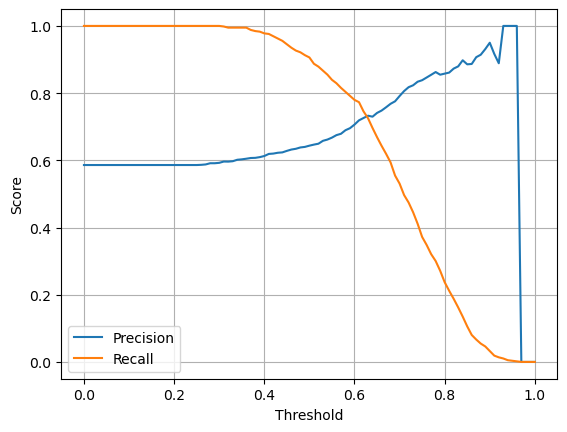

In [63]:
plt.plot(thresholds, precisions, label="Precision")
plt.plot(thresholds, recalls, label="Recall")

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid()
plt.show()

In [69]:
differences = np.abs(np.array(precisions) - np.array(recalls))
differences[60:71]

array([0.07352654, 0.05398992, 0.01982017, 0.00750265, 0.03362904,
       0.07207881, 0.10467116, 0.13837489, 0.17435527, 0.22104882,
       0.26063188])

In [81]:
best_index = np.argmin(np.where((np.array(precisions) != 0) | (np.array(recalls) != 0), differences, np.inf))

thresholds[best_index]

0.63

In [87]:
# Question 4: F1 score

f1_scores = []

for p, r, in zip(precisions, recalls):
    if p + r == 0:
        f1_scores.append(0)
    else:
        f1_scores.append(2 * p * r / (p + r))

In [89]:
thresholds[np.argmax(f1_scores)]

0.41000000000000003

In [91]:
# Question 5: 5-Fold CV

kfold = KFold(n_splits=5, shuffle=True, random_state=1)
auc_scores = []

# Repeat the process for each of the five folds
for train_idx, val_idx in kfold.split(df_full_train):

    # Select the rows 
    df_train_fold = df_full_train.iloc[train_idx].copy()
    df_val_fold = df_full_train.iloc[val_idx].copy()

    # Separate target column
    y_train_fold = df_train_fold["converted"].values
    y_val_fold = df_val_fold["converted"].values

    # Remove target from the feature data
    X_train_fold_df = df_train_fold.drop(columns=["converted"])
    X_val_fold_df = df_val_fold.drop(columns=["converted"])

    # Convert the feature data into dictionaries
    train_dicts_fold = X_train_fold_df.to_dict(orient="records")
    val_dicts_fold = X_val_fold_df.to_dict(orient="records")

    # Encode the features as numbers
    dv_fold = DictVectorizer(sparse=True)
    X_train_fold = dv_fold.fit_transform(train_dicts_fold)
    X_val_fold = dv_fold.transform(val_dicts_fold)

    # Train the model
    model_fold = LogisticRegression(
        solver="liblinear",
        C=1.0,
        max_iter=1000
    )
    model_fold.fit(X_train_fold, y_train_fold)

    # Predict probabilities and calculate AUC
    y_pred_fold = model_fold.predict_proba(X_val_fold)[:, 1]
    auc_fold = roc_auc_score(y_val_fold, y_pred_fold)

    # Save this fold's AUC score
    auc_scores.append(auc_fold)

In [93]:
auc_scores

[0.7305601027122453,
 0.7295726148196622,
 0.7363428071259397,
 0.7412454717957564,
 0.7209138590326581]

In [95]:
np.std(auc_scores)

0.006853233151022138

In [97]:
# Question 6: Hyperparameter tuning

# Values of C to test
C_values = [0.000001, 0.001, 1]

# Store the results for each C value
cross_validation_results = []


for C in C_values:

    fold_auc_scores = []

    # Run five-fold cross-validation
    for train_idx, val_idx in kfold.split(df_full_train):

        # Select training and validation rows
        df_train_fold = df_full_train.iloc[train_idx].copy()
        df_val_fold = df_full_train.iloc[val_idx].copy()

        # Separate target column
        y_train_fold = df_train_fold["converted"].values
        y_val_fold = df_val_fold["converted"].values

        # Remove target from the feature data
        X_train_fold_df = df_train_fold.drop(columns=["converted"])
        X_val_fold_df = df_val_fold.drop(columns=["converted"])

        # Convert feature data into dictionaries
        train_dicts_fold = X_train_fold_df.to_dict(orient="records")
        val_dicts_fold = X_val_fold_df.to_dict(orient="records")

        # Encode features
        dv_fold = DictVectorizer(sparse=True)
        X_train_fold = dv_fold.fit_transform(train_dicts_fold)
        X_val_fold = dv_fold.transform(val_dicts_fold)

        # Train the model using the current C value
        model_fold = LogisticRegression(
            solver="liblinear",
            C=C,
            max_iter=1000
        )
        model_fold.fit(X_train_fold, y_train_fold)

        # Predict probabilities and calculate AUC
        y_pred_fold = model_fold.predict_proba(X_val_fold)[:, 1]
        auc_fold = roc_auc_score(y_val_fold, y_pred_fold)

        # Save this fold's AUC score
        fold_auc_scores.append(auc_fold)

    # Calculate the mean and standard deviation across five folds
    mean_auc = np.mean(fold_auc_scores)
    std_auc = np.std(fold_auc_scores)

    # Save the summary for this C value
    cross_validation_results.append({
        "C": C,
        "mean_auc": mean_auc,
        "std_auc": std_auc
    })


In [99]:
for result in cross_validation_results:
    print(
        f"C={result['C']}: "
        f"mean AUC={result['mean_auc']:.3f}, "
        f"std={result['std_auc']:.3f}"
    )

C=1e-06: mean AUC=0.617, std=0.019
C=0.001: mean AUC=0.749, std=0.010
C=1: mean AUC=0.732, std=0.007
